# Compare population products on their native support

**Learning question:** How do coverage, population concept and partial-cell overlap change an estimate for the same rectangle?

Three complete local source notebooks compare real Greater Lagos WorldPop, GRID3, LandScan and GHS-POP native count cells with an independent oracle.

This introductory calculation is an original **synthetic** teaching exercise. Full source lessons and their actual data status are separately described below.


## Predict before running

Count cells contain modelled people on native grids; density is a display quantity. The Population source course retains native offsets instead of resampling products onto a common grid. Residential and ambient population concepts and their reference dates differ. NoData is missing evidence; numeric zero is a valid value. Agreement among products sharing inputs is not independent validation.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Synthetic partial-cell total: 140.0
Synthetic count support comparison | modelled people: {'whole cells': 200, 'area-fraction estimate': 140.0}


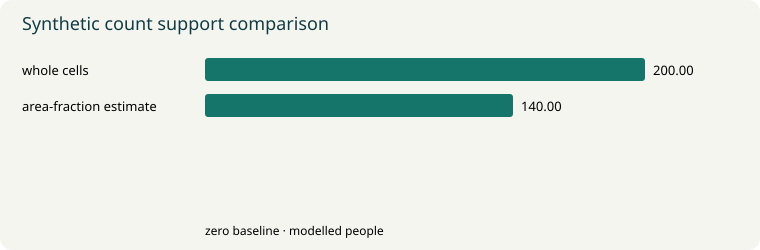

In [2]:
cells = [{'people':120,'fraction':1.0}, {'people':80,'fraction':0.25}, {'people':0,'fraction':0.5}]
weighted = sum(c['people']*c['fraction'] for c in cells)
print('Synthetic partial-cell total:', weighted)
bars({'whole cells':sum(c['people'] for c in cells),'area-fraction estimate':weighted}, 'Synthetic count support comparison', 'modelled people')


## Interpret the result

The synthetic example gives 140 people under a uniform-within-cell assumption, compared with 200 if every intersected cell is counted in full. Neither is ground truth. The actual source lessons below use credited real model products and spherical overlap areas, then reproduce a shared rectangle against a separately prepared oracle.

## Change one thing

Change the partial overlap from 0.25 to 0.75 and explain the implicit within-cell assumption. Then open all three source notebooks: compare the independent oracle, inspect native cells and coverage, and export results while retaining every product citation and modification field.


## Source course and scientific boundaries

The complete population.json and independent_oracle.json are local siblings of the three source notebooks, along with population_tools.py and its exact population_tools_real.py alias. The source uses standard-library Python. First browser runtime retrieval needs networking; the population calculations then read local inputs. Exports retain provenance. No full TIFF viewer or arbitrary-raster GIS capability is claimed.

[Complete local course guide](../../courses/population-data-comparison/index.ipynb) · [Notebook library](../../notebook-library.ipynb)


## Sources, attribution and limits

[Reviewed source README](https://github.com/jltobias/JupyterLite-Population-Data-Comparison/blob/883792b4f390e4e021ccc262dd5d4fd9f6250f3e/README.md) · [Source repository](https://github.com/jltobias/JupyterLite-Population-Data-Comparison)

Source JSON contains real modelled Greater Lagos excerpts, not observed individual people. WorldPop 2025/GRID3 2025, LandScan ambient 2020 and GHS-POP projected residential 2025 differ in concept and date. All selected excerpts retain CC BY 4.0 creator/version/source/modification metadata. The broader TIFF viewer remains an external continuation; browser Range/CORS and provider restrictions are separate from local JSON notebook execution.

- [Read source Book](https://jltobias.github.io/JupyterLite-Population-Data-Comparison/book/intro.html) — HTTP 200 - entry only
- [Open source Lab](https://jltobias.github.io/JupyterLite-Population-Data-Comparison/lab/lab/index.html?path=01_real_population.ipynb) — HTTP 200 - entry only
- [Open source explorer](https://jltobias.github.io/JupyterLite-Population-Data-Comparison/viewer/index.html) — HTTP 200 - entry only

[Central references](../../references.ipynb)
